# 18 - Keep only what you can vouch for: conformal factuality

> "Quill writes explainers. Can we publish them with a promise that every fact in nine out of ten explainers is correct?" - Quill Learning content lead

Read the request twice, because it is sharper than it sounds. The content lead is not asking
for facts that are right nine times in ten. She is asking for explainers, nine in ten of
which contain no false fact at all. Quill cannot be made to know more chemistry by Monday,
but it can be made to say less: drop the claims it is least sure of and publish the rest. The
statistical question is whether there is a rule for dropping claims, set once on explainers
we have graded, such that a new explainer, after the rule has run, has every remaining claim
true with probability at least 1 - alpha. It must hold in finite samples, for any model, and
come with an honest price tag: how many true claims the rule throws away to keep the promise.
The rule exists. It is **conformal factuality** (Mohri and Hashimoto, 2024), and it is split
conformal prediction from notebook 02 applied to one number per explainer.

**What you will learn**

- How a long answer becomes a bundle of graded claims, and why the grader (its reference, its
  tolerances, and what it cannot grade) is part of the guarantee (field guide §27).
- The conformal factuality recipe from scratch: one nonconformity score per explainer (the
  score of its most convincing false claim), notebook 02's corrected quantile, keep what
  scores above it; and why this is notebook 03's leaderboard argument with one tile per
  explainer.
- Why validity is free and usefulness is earned here too: two claim scores keep the same
  promise and very different shares of the truth (field guide §5), and why, with a dozen
  errors to learn from, a learned score is worth no more than the same explainers spent on
  calibration.
- Why explainers, not claims, are the units, and how to check the promise on a population you
  did not calibrate on.

**Where we are in the series.** Notebook 16 measured the three ways Quill reports certainty
and why the whole procedure must stay fixed; notebook 17 turned option probabilities into
answer shortlists. This notebook moves from short answers to long ones. It leans on notebook
02 (the corrected quantile, the three-way split), notebook 03 (the leaderboard argument and
the coverage lottery) and notebook 09, whose section 3 calibrated with one tile per building:
here every tile is an explainer. Notebook 19 closes Part III with retrieval depth and
conformal risk control.

In [1]:
import math
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 140)
RANDOM_SEED = 20260707
ALPHA = 0.10   # the product's 90% promise

# Series palette: blue = data, green = covered/healthy, amber = calibration/warning,
# red = missed/fault/naive, gray = reference, purple = alternative method.
BLUE, GREEN, AMBER, RED, GRAY, PURPLE = (
    "#2563EB", "#059669", "#F59E0B", "#DC2626", "#6B7280", "#7C3AED",
)

## 1. An explainer is a bundle of claims

Quill's explainers in this notebook are profiles of the 118 chemical elements. The data is
real model output, generated once with `gpt-4.1-mini` and cached in `llm_data/` (notebook 16
tells the provenance story and why the cached files, not a fresh run, are the reference). For
each element the model was asked, at temperature 0, for a short factual profile written as a
list of claims, one per attribute: atomic number, symbol, atomic mass, standard state, group
block, year of discovery, melting point, boiling point, density, electronegativity and first
ionization energy. Each claim came with a one-sentence statement, the value alone, and the
model's own confidence from 0 to 100. The same request was then sent five more times at
temperature 1.0, to see whether the model repeats itself.

A **claim** is one atomic statement inside a long answer: here, one sentence carrying one
checkable value. A long answer is a bundle of claims, and the content lead's promise is about
the bundle. We call each element's profile an explainer, and we start by reading one.

In [2]:
claims = pd.read_csv("llm_data/element_claims.csv")
pubchem = pd.read_csv("llm_data/pubchem_elements.csv")
claims["gradable"] = claims["correct"].notna()   # empty `correct` = PubChem has no value

per_element = claims.groupby("element").size()
print(f"{len(claims):,} claims about {claims['element'].nunique()} elements "
      f"(PubChem table: {len(pubchem)} elements), {per_element.min()} to {per_element.max()} "
      f"claims per explainer")
print(f"gradable against PubChem: {claims['gradable'].sum():,}   "
      f"ungradable (no PubChem value): {(~claims['gradable']).sum()}")
all_attributes = set(claims["attribute"])
short = per_element[per_element < len(all_attributes)].index
print("explainers missing a claim: " + "; ".join(
    f"{e} (no {', '.join(sorted(all_attributes - set(claims.loc[claims['element'] == e, 'attribute'])))})"
    for e in short))

# The grader (below) reads the returned value, not the sentence. Check the format once, and
# whether the sentence a student reads says the same thing.
MEASURED = ["atomic_mass", "melting_point", "boiling_point", "density", "electronegativity",
            "ionization_energy"]
values = claims["claimed_value"].astype(str).str.strip().str.replace(",", "")
measured = claims["attribute"].isin(MEASURED)
atomic = claims["attribute"] == "atomic_number"
bare = values[measured].str.fullmatch(r"[-+]?(\d+\.?\d*|\.\d+)([eE][-+]?\d+)?")
whole = values[atomic].str.fullmatch(r"\d+")
print(f"measured values that are a bare number: {int(bare.sum())} of {int(measured.sum())}; "
      f"atomic numbers that are a whole number: {int(whole.sum())} of {int(atomic.sum())}")
repeats = np.array([str(v).lower() in str(s).lower().replace(",", "")   # thousands separators aside
                    for v, s in zip(claims["claimed_value"], claims["sentence"])])
print(f"sentences that repeat their returned value: {repeats.sum():,} of {len(claims):,}")
for r in claims[~repeats].itertuples():
    print(f"  does not: {r.element} {r.attribute}, value {r.claimed_value}: {r.sentence}")

# One explainer, read as the content lead would: sentence by sentence.
example = claims[claims["element"] == "Ruthenium"]
print("\nThree of Quill's sentences about ruthenium:")
for sentence in example["sentence"].iloc[5:8]:
    print("  ", sentence)
example[["attribute", "claimed_value", "true_value", "correct",
         "stated_confidence", "resample_agreement"]].reset_index(drop=True)

1,296 claims about 118 elements (PubChem table: 118 elements), 10 to 11 claims per explainer
gradable against PubChem: 1,197   ungradable (no PubChem value): 99
explainers missing a claim: Meitnerium (no boiling_point); Roentgenium (no boiling_point)
measured values that are a bare number: 706 of 706; atomic numbers that are a whole number: 118 of 118
sentences that repeat their returned value: 1,295 of 1,296
  does not: Hydrogen density, value 8.988e-05: Hydrogen has a density of approximately 0.00008988 g/cm³ at standard temperature and pressure.

Three of Quill's sentences about ruthenium:
   Ruthenium was discovered in the year 1844.
   Ruthenium has a melting point of about 2334 kelvin.
   Ruthenium has a boiling point near 4150 kelvin.


,attribute,claimed_value,true_value,correct,stated_confidence,resample_agreement
0,atomic_number,44,44,True,100.0,5
1,symbol,Ru,Ru,True,100.0,5
2,atomic_mass,101.07,101.1,True,95.0,5
3,standard_state,Solid,Solid,True,100.0,5
4,group_block,Transition metal,Transition metal,True,100.0,5
5,year_discovered,1844,1827,False,95.0,5
6,melting_point,2334,2607.0,False,90.0,3
7,boiling_point,4150,4423.0,False,85.0,3
8,density,12.45,12.1,True,90.0,5
9,electronegativity,2.2,2.2,True,90.0,5


The file holds 1,296 claims about the 118 elements, 10 or 11 per explainer: 118 times 11 would
be 1,298, and the two missing claims are the boiling points of meitnerium and roentgenium, for
which the model gave no value (the generator records only claims that carry one). Of the
1,296, 1,197 can be checked against PubChem and 99 cannot.

Ruthenium shows what the content lead is up against. Eleven fluent sentences, and three of
them are false: the discovery year (1844 against PubChem's 1827), the melting point (2334 K
against 2607 K) and the boiling point (4150 K against 4423 K). The two temperatures are not
guesses: they are ruthenium's melting and boiling points in degrees Celsius, labelled kelvin,
exactly 273 below PubChem's values. Nothing in the prose marks any of the three. The model's confidence on the three false claims, 95, 90 and
85, is no lower than on true ones such as the density (90) or the ionization energy (85), and
the five resampled profiles repeated the wrong year every time (agreement 5). Whatever rule we
build has to work with signals this blunt.

Before any number, the rule that decides what "true" means. The **grader** is the function
`grade` in `llm_data/generate_llm_data.ipynb`; section 5 copies it verbatim and checks that it
reproduces every label in the file. Here it is in words:

| Attribute | Counted true when | Plain-English note |
|---|---|---|
| `atomic_number` | the value is a whole number equal to PubChem's | exact; "44.6" is false, not truncated to 44 |
| `symbol`, `standard_state`, `group_block` | the text matches PubChem's, ignoring case, after dropping PubChem's prefix "Expected to be a" | oganesson "Solid" against PubChem's "Expected to be a Gas" is false |
| `atomic_mass` | within 1% | PubChem rounds some masses (lithium is 7.0) |
| `melting_point`, `boiling_point`, `density` | within 5% | relative tolerance |
| `ionization_energy` | within 3% | relative tolerance |
| `electronegativity` | within 0.1 on the Pauling scale | absolute tolerance |
| `year_discovered` | within 2 years; PubChem's "Ancient" matches "ancient" or any year before 1600 | what counts as "discovered" is not checked |

Two rules apply before any row of the table. The grader reads the value Quill returned in the
structured part of its reply, not the sentence a student reads, and it reads that value strictly: a
measured value (mass, temperature, density, electronegativity, ionization energy) is graded only
when it is a bare number, which the grader reads as being in the unit the prompt asked for, and an
atomic number must be a whole number. So even a correct "2607 K (2334 C)" for ruthenium would be
ungradable, never true. The grader cannot check units, only assume them: a bare 2334 that is
really degrees Celsius is read as kelvin, which is why ruthenium's two temperatures count as false
rather than ungradable. These
format rules are stricter than taking the first number found in the value, and on this file they
change no label: the checks printed above find all 706 measured values bare numbers and all 118
atomic numbers whole. Nothing in the grader compares the sentence with the value, so we did it
once: 1,295 of the 1,296 sentences repeat their value (thousands separators aside), and the
exception, hydrogen's density, writes the same number out as 0.00008988. Every
guarantee in this notebook is therefore agreement with this rubric and its tolerances, applied to
the returned values; a sentence that said something else would be published under a promise that
never read it.

A claim is **ungradable** when PubChem has no value to check it against (the format rule would also
make a measured value that is not a bare number ungradable; none occurs here). Our policy:
ungradable claims are excluded. In calibration and evaluation they are removed from the
explainer, so every promise below is a promise about checkable claims. Counting them as true would make
the promise look stronger than it is, since a claim nobody grades can never break it; counting
them as false would punish the model for PubChem's gaps. In the product, an ungradable claim
needs another source or a human reviewer, and the published promise must say that it covers
only what was checked. At deployment no grader runs, so the filter itself runs on every claim
of a new explainer, and the promise covers its kept claims of the kinds the grader can check;
which kinds those are comes from the reference (PubChem lists the values it lacks). A kept
claim of an uncheckable kind is withheld, not published unverified, until a reviewer or another
source confirms it. Section 5 shows where these claims sit and how many of them the filter
would keep.

In [3]:
# The ungradable policy: excluded. A claim the grader cannot check is removed from the
# bundle before the filter, so the promise below is about checkable claims only.
graded = claims[claims["gradable"]].copy()       # keeps the original claim index
graded["correct"] = graded["correct"].astype(bool)

explainer_ok = graded.groupby("element")["correct"].all()
claim_accuracy = graded["correct"].mean()
claims_per_explainer = graded.groupby("element").size().mean()
print(f"gradable claims: {len(graded):,}   correct: {claim_accuracy:.1%}   "
      f"false: {int((~graded['correct']).sum())}")
print(f"explainers with at least one false claim: {int((~explainer_ok).sum())} of "
      f"{len(explainer_ok)} ({(~explainer_ok).mean():.1%})")
print(f"if claims failed independently at {1 - claim_accuracy:.1%}, an explainer of "
      f"{claims_per_explainer:.1f} graded claims would contain an error "
      f"{1 - claim_accuracy ** claims_per_explainer:.1%} of the time")

by_attribute = graded.groupby("attribute")["correct"].agg(
    graded_claims="size", false_claims=lambda s: int((~s).sum()))
by_attribute["error_rate"] = by_attribute["false_claims"] / by_attribute["graded_claims"]
by_attribute["ungradable"] = (claims[~claims["gradable"]].groupby("attribute").size()
                              .reindex(by_attribute.index, fill_value=0))
by_attribute.sort_values("error_rate", ascending=False).round(3)

gradable claims: 1,197   correct: 97.3%   false: 32
explainers with at least one false claim: 25 of 118 (21.2%)
if claims failed independently at 2.7%, an explainer of 10.1 graded claims would contain an error 24.0% of the time


,graded_claims,false_claims,error_rate,ungradable
attribute,,,,
year_discovered,118,10,0.085,0
boiling_point,93,7,0.075,23
density,96,6,0.062,22
melting_point,103,4,0.039,15
ionization_energy,102,2,0.020,16
atomic_mass,118,2,0.017,0
standard_state,118,1,0.008,0
atomic_number,118,0,0.000,0
electronegativity,95,0,0.000,23


Here is the gap between the two readings of the request. Per claim, Quill looks excellent:
97.3% of the 1,197 gradable claims are correct, 32 are false. Per explainer, it does not: 25 of
the 118 explainers, 21.2%, contain at least one false claim, so a reader picking an explainer
at random has about one chance in five of being misled somewhere in it. The independence
arithmetic says the same thing from the other side: if each of about 10.1 graded claims failed
independently at 2.7%, an explainer would contain an error 24.0% of the time. The observed
21.2% is close, so the errors are not wildly bunched; they are simply numerous enough that a
ten-fact answer collects one. The content lead's target, at most one flawed explainer in ten,
is not met by the raw model.

The table says where the errors live. Discovery years lead (10 false out of 118, 8.5%),
followed by boiling points (7.5%), densities (6.2%), melting points (3.9%), ionization
energies (2.0%), atomic masses (1.7%) and standard states (0.8%). Atomic numbers, symbols,
group blocks and electronegativities have no error at all. The ungradable claims are all
physical measurements: boiling points (23), electronegativities (23), densities (22),
ionization energies (16) and melting points (15). What the table cannot say is whether every
false claim is false in the sense a chemist would mean. That is the next cell.

In [4]:
false_claims = graded[~graded["correct"]]
print("Every false discovery year, in Quill's words, against PubChem:")
for _, row in false_claims[false_claims["attribute"] == "year_discovered"].iterrows():
    print(f"  {row['element']:<13} {row['sentence']:<62} PubChem: {row['true_value']}")
print("\nEvery false density:")
for _, row in false_claims[false_claims["attribute"] == "density"].iterrows():
    ratio = float(row["claimed_value"]) / float(row["true_value"])
    print(f"  {row['element']:<13} claimed {row['claimed_value']:>6} g/cm3, PubChem "
          f"{row['true_value']:>8}  (ratio {ratio:,.0f})")
print("\nEvery false melting or boiling point, in kelvin:")
temps = false_claims[false_claims["attribute"].isin(["melting_point", "boiling_point"])]
gaps = temps["true_value"].astype(float) - temps["claimed_value"].astype(float)
for (_, row), gap in zip(temps.iterrows(), gaps):
    print(f"  {row['element']:<13} {row['attribute']:<14} claimed {row['claimed_value']:>5}, "
          f"PubChem {float(row['true_value']):>5.0f}  (PubChem minus claim {gap:+5.0f})")
print(f"exactly 273 K below PubChem, i.e. degrees Celsius written as kelvin: "
      f"{int((gaps == 273).sum())} of {len(temps)}")

Every false discovery year, in Quill's words, against PubChem:
  Helium        Helium was discovered in the year 1895.                        PubChem: 1868
  Fluorine      Fluorine was discovered in the year 1886.                      PubChem: 1670
  Aluminum      Aluminum was first isolated in the year 1825.                  PubChem: Ancient
  Silicon       Silicon was first isolated in the year 1824.                   PubChem: 1854
  Calcium       Calcium was discovered in the year 1808.                       PubChem: Ancient
  Ruthenium     Ruthenium was discovered in the year 1844.                     PubChem: 1827
  Bismuth       Bismuth was known since ancient times.                         PubChem: 1753
  Protactinium  Protactinium was discovered in the year 1917.                  PubChem: 1913
  Bohrium       Bohrium was discovered in the year 1981.                       PubChem: 1976
  Oganesson     Oganesson was discovered in the year 2002.                     PubChem: 2006



Two kinds of "false" sit in this printout, and the guarantee will treat them identically.

The densities and temperatures hold ten plain unit slips. Fluorine, chlorine, xenon and radon are
gases, and Quill gave each of them a density about 1,000 times PubChem's: the right digits for
grams per litre, labelled grams per cubic centimetre. Six of the 11 false melting and boiling
points are exactly 273 K below PubChem's (ruthenium's two, praseodymium's two, gadolinium's
boiling point and nobelium's melting point): the temperature in degrees Celsius, written as
kelvin. Curium's two, 278 and 290 below, look like the same slip against slightly different
reference values. A unit slip is still a false published claim, and a student would be misled
by every one of them. The remaining misses are of another sort: radium (5.5 against 5.0) and
berkelium (14.78 against 14.0) are close calls, the kind of gap you find between two reference
tables, and the boiling points of yttrium, radium and americium miss by 415 to 597 K in both
directions.

The discovery years are mostly a quarrel about a definition. Aluminum and silicon are given
the year they were "first isolated", which is what the sentence says; PubChem lists aluminum
as "Ancient" and silicon as 1854. Helium's 1868 in PubChem is the year it was first seen in
the solar spectrum; 1895, Quill's year, is when it was isolated on Earth. Bismuth was "known
since ancient times" for Quill and dates from 1753 for PubChem; calcium is the reverse. A
historian would accept several of these ten. Our grader does not, and we will not relabel
anything: the grader is the contract, and rewriting it after seeing which claims failed would
be tuning the promise on its own test. One caution to carry forward: whatever the filter
promises, it promises it about this grader (field guide §27). Section 5 measures what a
different grader does to the promise.

## 2. Two claim scores

The recipe in section 3 needs one number per claim, higher for claims more likely to be true.
The data offers two, both introduced in notebook 16 for multiple-choice answers:

- Resample agreement (`resample_agreement`, notebook 16's self-consistency): how many of the
  five profiles resampled at temperature 1.0 gave the identical value for the same attribute,
  from 0 to 5. "Identical" means the same text, ignoring case, so "2334" and "2333" disagree,
  and a numeric claim can be right and still score low.
- Stated confidence (`stated_confidence`, notebook 16): the number from 0 to 100 that Quill
  wrote next to each claim, in the same reply.

Neither is a probability we should believe (field guide §24). For the recipe they do not have
to be calibrated at all: they only have to rank claims, true ones above false ones. So we ask
the ranking question directly: at each score level, what share of the claims is false?

AUC, true above false: resample agreement 0.594   stated confidence 0.783
claims at agreement 5: 1,040 of 1,197, of which false 22 (2.1%)
false claims that all five resampled profiles repeated (agreement 5): 22 of 32
true claims below agreement 5: 147, of which numeric measurements: 137
claims at confidence 100: 612, of which false 2 (0.3%): Helium year_discovered, Oganesson year_discovered


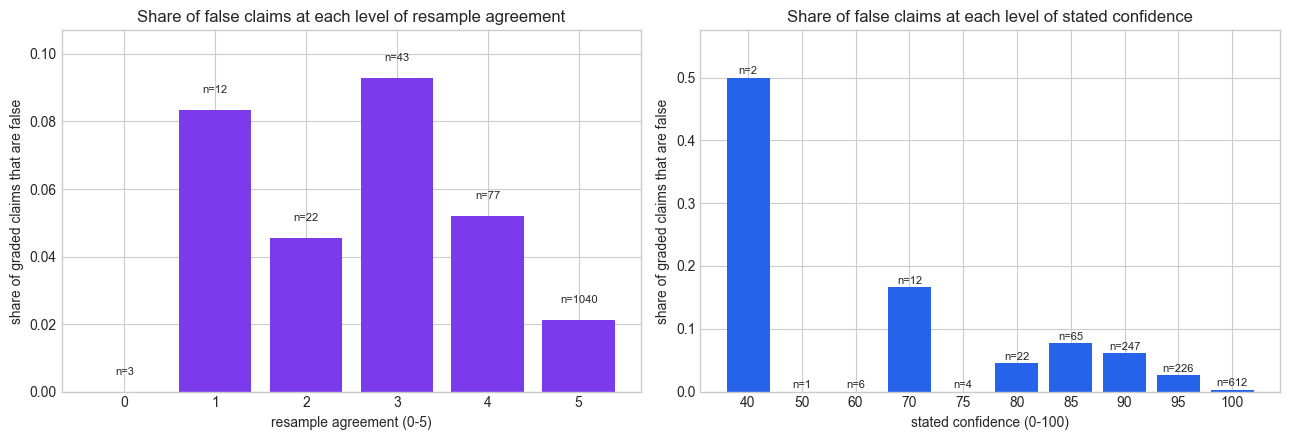

claims  false  error_rate
score              level                           
resample agreement 0.0         3      0       0.000
                   1.0        12      1       0.083
                   2.0        22      1       0.045
                   3.0        43      4       0.093
                   4.0        77      4       0.052
                   5.0      1040     22       0.021
stated confidence  40.0        2      1       0.500
                   50.0        1      0       0.000
                   60.0        6      0       0.000
                   70.0       12      2       0.167
                   75.0        4      0       0.000
                   80.0       22      1       0.045
                   85.0       65      5       0.077
                   90.0      247     15       0.061
                   95.0      226      6       0.027
                   100.0     612      2       0.003

In [5]:
def error_by_level(df, col):
    """Claims, false claims and error rate at each level of a claim score."""
    table = df.groupby(col)["correct"].agg(claims="size", false=lambda s: int((~s).sum()))
    table["error_rate"] = table["false"] / table["claims"]
    return table


agreement_table = error_by_level(graded, "resample_agreement")
confidence_table = error_by_level(graded, "stated_confidence")

# AUC in words: the chance that a randomly chosen true claim outscores a randomly chosen
# false one (ties count one half). 0.5 is a coin, 1.0 is a perfect ranking.
auc = {"resample agreement": roc_auc_score(graded["correct"], graded["resample_agreement"]),
       "stated confidence": roc_auc_score(graded["correct"], graded["stated_confidence"])}
top_agree = graded["resample_agreement"] == 5
top_conf = graded["stated_confidence"] == 100
low_true = graded[graded["correct"] & ~top_agree]
print(f"AUC, true above false: resample agreement {auc['resample agreement']:.3f}   "
      f"stated confidence {auc['stated confidence']:.3f}")
print(f"claims at agreement 5: {top_agree.sum():,} of {len(graded):,}, of which false "
      f"{int((top_agree & ~graded['correct']).sum())} ({1 - graded.loc[top_agree, 'correct'].mean():.1%})")
print(f"false claims that all five resampled profiles repeated (agreement 5): "
      f"{int((top_agree & ~graded['correct']).sum())} of {int((~graded['correct']).sum())}")
print(f"true claims below agreement 5: {len(low_true)}, of which numeric measurements: "
      f"{int(low_true['attribute'].isin(MEASURED).sum())}")
print(f"claims at confidence 100: {top_conf.sum():,}, of which false "
      f"{int((top_conf & ~graded['correct']).sum())} ({1 - graded.loc[top_conf, 'correct'].mean():.1%}): "
      f"{', '.join(graded.loc[top_conf & ~graded['correct'], 'element'] + ' ' + graded.loc[top_conf & ~graded['correct'], 'attribute'])}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, table, label, color in [(axes[0], agreement_table, "resample agreement (0-5)", PURPLE),
                                (axes[1], confidence_table, "stated confidence (0-100)", BLUE)]:
    xs = np.arange(len(table))
    ax.bar(xs, table["error_rate"], color=color)
    for x, (n, rate) in enumerate(zip(table["claims"], table["error_rate"])):
        ax.text(x, rate + 0.005, f"n={n}", ha="center", fontsize=8)
    ax.set_xticks(xs, [f"{v:g}" for v in table.index])
    ax.set_ylim(0, table["error_rate"].max() * 1.15)
    ax.set_title(f"Share of false claims at each level of {label.split(' (')[0]}")
    ax.set_xlabel(label)
    ax.set_ylabel("share of graded claims that are false")
plt.tight_layout()
plt.show()

pd.concat({"resample agreement": agreement_table, "stated confidence": confidence_table},
          names=["score", "level"]).round(3)

The two scores are not in the same league. Resample agreement barely ranks claims: its AUC is
0.594, a little better than a coin. The reason is visible in the left panel. 1,040 of the
1,197 claims sit at the top level, 5, and they are not clean: 22 of them are false. Their
error rate, 2.1%, is lower than at levels 1 to 4 (4.5% to 9.3%), but the top level holds 22
of the 32 false claims. When Quill is wrong about a fact, it is usually wrong consistently,
and resampling measures consistency, not truth. The bottom levels, meanwhile, are crowded
with true claims: 137 of the 147 true claims below agreement 5 are numeric measurements, where
"identical text" punishes harmless differences in rounding.

Stated confidence ranks much better, with an AUC of 0.783. Its top level, 100, holds 612
claims of which 2 are false (0.3%): helium's discovery year and oganesson's. The error rate
then climbs as the stated confidence falls: 2.7% at 95, 6.1% at 90, 7.7% at 85. Below 85 the
counts are too small to read (two claims at 40, one at 50, six at 60). What this does not
mean: that a stated 90 is a 90% chance of being right. Claims stated at 90 are right 93.9% of
the time here and claims stated at 85 92.3%; checking calibration is notebook 16's job, and the
recipe does not need it. Nor does a good AUC settle the matter: it is an average over all pairs
of claims, while the recipe will care about something more specific, namely where each
explainer's most convincing false claim sits. That is section 3.

## 3. The recipe

Here is conformal factuality in words, before any symbol.

1. **Score** every claim, higher meaning more trustworthy (agreement or stated confidence).
2. **Find each calibration explainer's most convincing false claim**: the highest score held by
   any of its false claims. If the explainer has no false claim, its number is minus infinity.
   This one number is the explainer's nonconformity score, notebook 02's weirdness meter: it
   says how high a bar must be to stop every false claim in this explainer.
3. **Take notebook 02's corrected quantile** of those numbers, one per calibration explainer.
4. **Filter**: in a new explainer, keep only the claims that score strictly above that bar.

Why this keeps the promise is short once the event is named. A new explainer comes
out of the filter with every kept claim true exactly when none of its false claims scores
above the bar, that is, exactly when its own number is at or below the bar. That is precisely
the bet notebook 03 analyzed: the newcomer's score lands at or below the corrected quantile of
the calibration scores. If the calibration explainers and the new one are exchangeable, the
newcomer's rank among them is uniform, and the bet wins with probability at least 1 - alpha.
The claims inside an explainer can be as correlated as they like, because the argument never
looks inside an explainer: it is notebook 09's one-tile-per-building construction (section 3
there) with one tile per explainer. In symbols, after the words:

$$S_i = \max\{\, s(c) : c \text{ is a false claim of explainer } i \,\}, \qquad S_i = -\infty \text{ if there is none,}$$

$$\hat t = \text{the corrected quantile of } S_1, \dots, S_n, \qquad \text{published claims} = \{\, c : s(c) > \hat t \,\},$$

$$\Pr(\text{every published claim of explainer } n+1 \text{ is true}) = \Pr(S_{n+1} \le \hat t) \ge 1 - \alpha,$$

where $s(c)$ is the score of claim $c$, $S_i$ the nonconformity score of explainer $i$, $n$ the
number of calibration explainers, $\hat t$ the bar, and the probability is over the draw of the
calibration explainers and the new one (and over the jitter introduced next). "Strictly above" matters: a claim exactly at the bar
can be the false claim that set it.

One trap before code: ties. Agreement takes six values and stated confidence about ten, so
hundreds of claims share the top levels. If the bar lands on a tied level, "strictly above" keeps
nothing at that level, all or nothing. We break ties the way notebook 17 did for sampled
answers: add a tiny uniform jitter, between 0 and 0.01, smaller than any gap between levels.
It decides at random which of the tied claims survive. It is a tie-breaking device, not new
information, and the guarantee survives it because the jitter is part of the score, drawn
independently for every claim. We implement everything from scratch, then split the 118
explainers at random into 59 for calibration and 59 for testing: explainers are the units we
split, never claims.

In [6]:
# Ties: agreement takes 6 values and confidence about 10, so many claims share a score.
# A tiny uniform jitter, smaller than any gap between levels, breaks the ties at random.
# It is a tie-breaking device, not new information.
jitter_rng = np.random.default_rng(RANDOM_SEED)
claims["agreement_score"] = claims["resample_agreement"] + jitter_rng.uniform(0, 0.01, len(claims))
claims["confidence_score"] = claims["stated_confidence"] + jitter_rng.uniform(0, 0.01, len(claims))
graded[["agreement_score", "confidence_score"]] = claims.loc[graded.index,
                                                             ["agreement_score", "confidence_score"]]

N_UNITS = 118                                    # one explainer per element
unit = graded["atomic_number"].to_numpy() - 1    # explainer id of each claim (0 = hydrogen)
correct = graded["correct"].to_numpy()


def explainer_scores(score, correct, unit, n_units=N_UNITS):
    """One nonconformity score per explainer: the highest score held by any FALSE claim.

    An explainer with no false claim gets minus infinity. Keeping only the claims that
    score strictly above a threshold t leaves an explainer with no false claim exactly
    when its explainer score is at or below t - so the per-explainer promise is a
    statement about one number per explainer, and notebook 03's leaderboard applies.
    """
    s = np.full(n_units, -np.inf)
    np.maximum.at(s, unit[~correct], score[~correct])
    return s


def corrected_quantile(scores, alpha):
    """The corrected quantile from notebook 02: the k-th smallest score, k = ceil((n+1)(1-alpha))."""
    n = len(scores)
    k = math.ceil((n + 1) * (1 - alpha))
    assert k <= n, "calibration window too short for this alpha (field guide S1)"
    return float(np.sort(scores)[k - 1])


def factuality_split(score, correct, unit, cal, test, alpha=ALPHA):
    """Calibrate the claim filter on the explainers in `cal`, grade it on those in `test`.

    Returns the threshold, the promise (share of test explainers whose kept claims are
    all true) and two prices: the share of true test claims kept, and the claims kept per
    test explainer. `cal` and `test` are arrays of explainer ids; they must not overlap.
    """
    s = explainer_scores(score, correct, unit)
    t = corrected_quantile(s[cal], alpha)
    in_test = np.isin(unit, test)
    kept = in_test & (score > t)
    return {"threshold": t,
            "explainers all true": float(np.mean(s[test] <= t)),
            "true claims kept": (kept & correct).sum() / (in_test & correct).sum(),
            "claims kept per explainer": kept.sum() / len(test)}


SCORES = {"resample agreement": "agreement_score", "stated confidence": "confidence_score"}

split_rng = np.random.default_rng(RANDOM_SEED + 1)
perm = split_rng.permutation(N_UNITS)
cal, test = perm[:59], perm[59:]                 # explainers are the units we split

rows = []
for name, col in [("resample agreement, raw ties", "resample_agreement"), *SCORES.items()]:
    score = graded[col].to_numpy(dtype=float)
    s_cal = explainer_scores(score, correct, unit)[cal]
    result = factuality_split(score, correct, unit, cal, test)
    rows.append({"score": name,
                 "calibration explainers with a false claim": int(np.isfinite(s_cal).sum()),
                 "six highest explainer scores": np.round(np.sort(s_cal)[::-1][:6], 3),
                 **result})

    # The shortcut "explainer score <= t" must equal the slow, literal check.
    kept_df = graded.assign(kept=score > result["threshold"])
    kept_df = kept_df[np.isin(unit, test)]
    literal = (~(kept_df["kept"] & ~kept_df["correct"])).groupby(kept_df["element"]).all().mean()
    assert np.isclose(literal, result["explainers all true"]), "shortcut and literal check disagree"

n_cal = len(cal)
rank = math.ceil((n_cal + 1) * (1 - ALPHA))       # the rank k the corrected quantile takes
print(f"{n_cal} calibration and {len(test)} test explainers; the corrected quantile picks the "
      f"{rank}th smallest of {n_cal} explainer scores, i.e. the {n_cal - rank + 1}th highest")
pd.DataFrame(rows).set_index("score").round(3)

59 calibration and 59 test explainers; the corrected quantile picks the 54th smallest of 59 explainer scores, i.e. the 6th highest


,calibration explainers with a false claim,six highest explainer scores,threshold,explainers all true,true claims kept,claims kept per explainer
score,,,,,,
"resample agreement, raw ties",14,"[5.0, 5.0, 5.0, 5.0, 5.0, 5.0]",5.000,1.000,0.000,0.000
resample agreement,14,"[5.009, 5.009, 5.009, 5.008, 5.008, 5.006]",5.006,0.915,0.287,2.932
stated confidence,14,"[95.009, 95.007, 95.005, 95.0, 90.008, 90.005]",90.005,0.864,0.807,8.085


Read the bookkeeping first. With 59 calibration explainers, the rank the leaderboard argument
needs is $\lceil 60 \times 0.9 \rceil = 54$: the corrected quantile is the 54th smallest of the
59 explainer scores, which is the 6th highest. So the bar is the sixth-highest explainer score:
the most convincing false claim of the explainer that ranks sixth (an explainer with two
convincing false claims counts once). Only 14 of the 59 calibration explainers hold a false
claim at all; the other 45 contribute minus infinity.

Now the three rows. With raw agreement, the six highest explainer scores are all 5.0, so the
bar is 5.0 and nothing scores strictly above it: the filter publishes empty explainers. The
promise is kept (1.000 of test explainers have no false published claim) in the most useless
way possible. With the jitter, the bar is 5.006 and the filter keeps the agreement-5 claims
whose jitter beats it: 28.7% of the true claims, 2.9 claims per explainer, and 0.915 of test
explainers fully correct. With stated confidence, the six highest explainer scores are
95.009, 95.007, 95.005, 95.0, 90.008 and 90.005, so the bar is 90.005: every claim stated at 95
or 100 is published, and so is any claim stated at 90 whose jitter beats 0.005. That keeps 80.7%
of the true claims, 8.1 claims per explainer. On this one split, 0.864 of the 59 test
explainers came out fully correct, below 0.90. One split of 59 explainers is one lottery
ticket (section 4), so the promise has to be judged over many splits, which is what this
section's last cell does. The assertion in the cell checked that the shortcut ("explainer score at or below the
bar") and the literal check (no false claim among the published ones) agree.

In [7]:
# Read one filtered explainer aloud: the test explainer with the most false claims.
score = graded["confidence_score"].to_numpy()
threshold = factuality_split(score, correct, unit, cal, test)["threshold"]
test_false = pd.Series(~correct).groupby(unit).sum().reindex(test)
shown = int(test_false.sort_values(ascending=False, kind="stable").index[0])
view = graded[unit == shown][["attribute", "claimed_value", "true_value", "correct",
                              "stated_confidence"]].copy()
view["kept"] = graded.loc[unit == shown, "confidence_score"] > threshold
print(f"threshold calibrated on the {len(cal)} calibration explainers: {threshold:.3f}")
print(f"{graded.loc[unit == shown, 'element'].iloc[0]}: {int(view['kept'].sum())} of {len(view)} "
      f"claims kept, {int((view['kept'] & ~view['correct']).sum())} of them false")
view.reset_index(drop=True)

threshold calibrated on the 59 calibration explainers: 90.005
Ruthenium: 7 of 11 claims kept, 1 of them false


,attribute,claimed_value,true_value,correct,stated_confidence,kept
0,atomic_number,44,44,True,100.0,True
1,symbol,Ru,Ru,True,100.0,True
2,atomic_mass,101.07,101.1,True,95.0,True
3,standard_state,Solid,Solid,True,100.0,True
4,group_block,Transition metal,Transition metal,True,100.0,True
5,year_discovered,1844,1827,False,95.0,True
6,melting_point,2334,2607.0,False,90.0,False
7,boiling_point,4150,4423.0,False,85.0,False
8,density,12.45,12.1,True,90.0,True
9,electronegativity,2.2,2.2,True,90.0,False


Ruthenium landed in the test half, and it is the test explainer with the most false claims. The
filter, with its bar at 90.005, publishes 7 of its 11 claims. It dropped both wrong
temperatures, the Celsius values stated at 90 and 85, and with them two true claims stated just
as low: the electronegativity (90) and the ionization energy (85). Among the three claims stated
at 90, the jitter decided: it kept the true density and dropped the false melting point and the
true electronegativity. It kept the wrong discovery year, stated at 95. The published ruthenium explainer is shorter and still wrong:
this is one of the failures the promise budgets for. The filter cannot tell a confident wrong
year from a confident right mass, because it sees only scores; all it controls is how often,
across explainers, a confident wrong claim gets through. One more subtlety: the promise says
nothing about which explainer fails. Ruthenium is not "90% likely to be right"; it is right or
wrong, and here it is wrong.

In [8]:
N_SPLITS = 1000
SPLITS = [split_rng.permutation(N_UNITS) for _ in range(N_SPLITS)]
has_false = np.isfinite(explainer_scores(np.zeros(len(graded)), correct, unit))
graded_per_explainer = np.bincount(unit, minlength=N_UNITS)

rows = []
for perm in SPLITS:
    cal, test = perm[:59], perm[59:]
    for name, col in SCORES.items():
        rows.append({"score": name, **factuality_split(graded[col].to_numpy(), correct, unit,
                                                       cal, test)})
    # Doing nothing: publish every claim. Its promise is the share of explainers with no error.
    rows.append({"score": "no filter", "threshold": -np.inf,
                 "explainers all true": float(np.mean(~has_false[test])),
                 "true claims kept": 1.0,
                 "claims kept per explainer": graded_per_explainer[test].mean()})
repeated = pd.DataFrame(rows)

summary = repeated.groupby("score", sort=False).agg(
    explainers_all_true=("explainers all true", "mean"),
    p05=("explainers all true", lambda s: s.quantile(0.05)),
    p95=("explainers all true", lambda s: s.quantile(0.95)),
    true_claims_kept=("true claims kept", "mean"),
    claims_kept_per_explainer=("claims kept per explainer", "mean"))
sem = repeated.groupby("score", sort=False)["explainers all true"].sem()   # simulation error of a mean
print(f"{N_SPLITS:,} random 59/59 splits of the explainers; rank argument: "
      f"{rank}/{n_cal + 1} = {rank / (n_cal + 1):.3f}; standard error of each mean below: at most {sem.max():.4f}")
summary.round(3)

1,000 random 59/59 splits of the explainers; rank argument: 54/60 = 0.900; standard error of each mean below: at most 0.0018


,explainers_all_true,p05,p95,true_claims_kept,claims_kept_per_explainer
score,,,,,
resample agreement,0.899,0.797,0.983,0.343,3.491
stated confidence,0.898,0.797,0.983,0.756,7.567
no filter,0.786,0.729,0.847,1.000,10.139


Over 1,000 random splits, the promise holds for both scores: 0.899 of test explainers are
fully correct after the agreement filter and 0.898 after the confidence filter. The rank
argument says what to expect from the 54th-of-59 bar: a new explainer passes with probability
54/60 = 0.900, and the two means are that value to within the simulation's own error (a
standard error of at most 0.0018 each), so a mean of 1,000 splits can land a hair either side
of it. Without a filter, the same test halves are fully correct 0.786 of the time, which is the
raw model's 21.2% flaw rate seen from the other side. Single splits wander: the 5th to 95th
percentiles run from 0.797 to 0.983 for both scores, which is what one ticket of 59 calibration
explainers graded on 59 test explainers looks like (section 4 takes this apart).

The same promise is bought at very different prices. The agreement filter publishes 34.3% of
the true claims, 3.5 claims of a 10.1-claim explainer. The confidence filter publishes 75.6%,
7.6 claims per explainer. Both are equally valid. Only one is a product.

## 4. What the guarantee costs

Alpha is the content lead's dial: one flawed explainer in ten, in twenty, in five, or three in
ten. We rerun the calibration step at five budgets on the same 1,000 splits and read off what each
costs: the true claims dropped, and the explainers left with nothing to publish. Next to each
achieved promise we print what the rank argument says the corrected quantile delivers at that
budget, $k/(n+1)$, where $k = \lceil (n+1)(1-\alpha) \rceil$ is the rank it takes among the
$n = 59$ calibration explainers.

splits in which the bar is minus infinity and every claim is published: alpha 0.05 0.0%, alpha 0.10 0.1%, alpha 0.15 4.3%, alpha 0.20 34.7%, alpha 0.30 98.3%


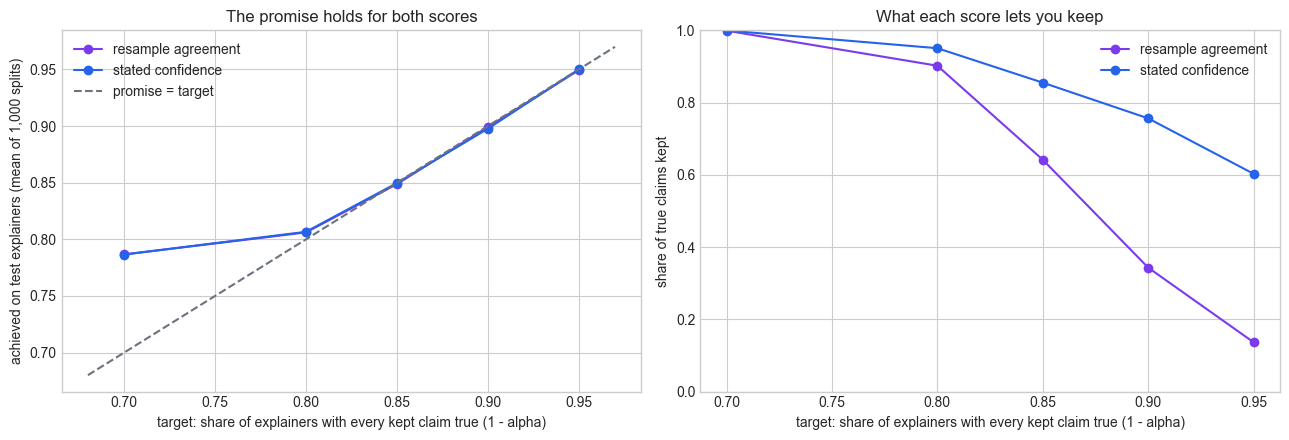

rank_argument  explainers_all_true  true_claims_kept  claims_kept_per_explainer  explainers_emptied
alpha score                                                                                                                  
0.05  resample agreement           0.95                0.949             0.136                      1.396               0.259
      stated confidence            0.95                0.950             0.603                      5.996               0.000
0.10  resample agreement           0.90                0.899             0.343                      3.491               0.030
      stated confidence            0.90                0.898             0.756                      7.567               0.000
0.15  resample agreement           0.85                0.849             0.642                      6.498               0.000
      stated confidence            0.85                0.850             0.855                      8.605               0.000
0.20  resample agreement           0.80                0.806             0.902                      9.134               0.000
      stated confidence            0.80                0.807             0.951                      9.618               0.000
0.30  resample agreement           0.70                0.787             0.999                     10.132               0.000
      stated confidence            0.70                0.787             1.000                     10.138               0.000

In [9]:
ALPHAS = [0.05, 0.10, 0.15, 0.20, 0.30]
rows = []
for perm in SPLITS:
    cal, test = perm[:59], perm[59:]
    for name, col in SCORES.items():
        score = graded[col].to_numpy()
        for a in ALPHAS:
            result = factuality_split(score, correct, unit, cal, test, alpha=a)
            # The bluntest price: a test explainer with no claim above the bar is published
            # empty, and an empty explainer keeps the promise without saying anything.
            kept_per_explainer = np.bincount(unit[score > result["threshold"]], minlength=N_UNITS)
            rows.append({"score": name, "alpha": a, **result,
                         "explainers emptied": np.mean(kept_per_explainer[test] == 0)})
sweep = pd.DataFrame(rows)


def conformal_rank(n, alpha):
    """Which order statistic (1 = smallest) the corrected quantile returns: k = ceil((n+1)(1-alpha))."""
    return math.ceil((n + 1) * (1 - alpha))


price = sweep.groupby(["alpha", "score"]).agg(
    explainers_all_true=("explainers all true", "mean"),
    true_claims_kept=("true claims kept", "mean"),
    claims_kept_per_explainer=("claims kept per explainer", "mean"),
    explainers_emptied=("explainers emptied", "mean")).reset_index()
price.insert(2, "rank_argument", [conformal_rank(59, a) / 60 for a in price["alpha"]])
# The bar is minus infinity (publish everything) when the k-th order statistic lands on a
# calibration explainer with no false claim; that depends on the split, not on the score.
bar_off = sweep[sweep["score"] == "stated confidence"].groupby("alpha")["threshold"].apply(
    lambda t: np.isinf(t).mean())
print("splits in which the bar is minus infinity and every claim is published: "
      + ", ".join(f"alpha {a:.2f} {v:.1%}" for a, v in bar_off.items()))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for name, color in [("resample agreement", PURPLE), ("stated confidence", BLUE)]:
    part = price[price["score"] == name]
    axes[0].plot(1 - part["alpha"], part["explainers_all_true"], marker="o", color=color, label=name)
    axes[1].plot(1 - part["alpha"], part["true_claims_kept"], marker="o", color=color, label=name)
axes[0].plot([0.68, 0.97], [0.68, 0.97], color=GRAY, linestyle="--", label="promise = target")
axes[0].set_title("The promise holds for both scores")
axes[0].set_xlabel("target: share of explainers with every kept claim true (1 - alpha)")
axes[0].set_ylabel("achieved on test explainers (mean of 1,000 splits)")
axes[0].legend()
axes[1].set_title("What each score lets you keep")
axes[1].set_xlabel("target: share of explainers with every kept claim true (1 - alpha)")
axes[1].set_ylabel("share of true claims kept")
axes[1].set_ylim(0, 1)
axes[1].legend()
plt.tight_layout()
plt.show()

price.set_index(["alpha", "score"]).round(3)

The left panel is the guarantee retargeting itself five times, for both scores at once:
0.949 or 0.950, 0.899 (agreement) and 0.898 (confidence), 0.849 or 0.850, 0.806 or 0.807, and
0.787, against the rank argument's 0.950, 0.900, 0.850, 0.800 and 0.700. The two lines sit on top
of each other because validity does not care which score you use (field guide §5): even a random
number would keep the promise. The first three points sit on their targets, to within the
simulation error of section 3. The last point sits well above its target, and the printout says
why: at alpha = 0.30 the bar is minus infinity in 98.3% of splits, because the order statistic it
needs lands among the calibration explainers with no false claim at all. The filter then
publishes everything and delivers about what the raw model delivers (0.786 unfiltered, section 3).
The same happens in 34.7% of splits at alpha = 0.20, which lifts that point a little above 0.80.
The rank argument's $k/(n+1)$ is exact only for distinct scores; a crowd of explainers tied at
minus infinity turns it into a floor.

The right panel is where the scores part company, and it is the panel the content lead should
negotiate over. At her 90%, the confidence filter keeps 75.6% of the true claims and the
agreement filter 34.3%. Asking for 95% drops the confidence filter from 75.6% to 60.3% (6.0
claims per explainer) and the agreement filter to 13.6%, 1.4 claims per explainer.
Relaxing to 80% lets the confidence filter keep 95.1%. The 80% end of the dial is cheap for a
reason: unfiltered explainers are fully correct 0.786 of the time, so a target of 0.80 asks
the filter to remove very little, and at 70% there is nothing left to remove: both filters keep
99.9% of the true claims or more. What the table does not license: reading 75.6% as
"the model's knowledge". It is the share of true claims that this score can separate from the
false ones at this budget; a better score would keep more of the same knowledge.

The last column is the bluntest form of the price: the share of test explainers left with no
claim at all. An empty explainer publishes nothing false, so the promise counts it as a success.
At 95% the agreement filter empties 25.9% of the explainers, which means 25.9 of its 94.9 points
are explainers with nothing in them; at 90% it empties 3.0%, and from 85% on almost none (at
most 0.03%). The confidence filter empties none at any level (0.000): at 95% its bar is the
third-highest explainer score, and with only two false claims stated at 100 in the whole file
(helium's and oganesson's discovery years, section 2), the bar never climbs past the level 95,
so every explainer keeps its claims stated at 100. It pays at 95% in claims instead, keeping
60.3% of the true ones. This is the trade-off Mohri and Hashimoto report for conformal factuality (ICML
2024): the higher the promised level, the more of the output is removed, until a filtered answer
can be uninformative or empty. Cherian, Gibbs and Candes (2024) offer one published remedy for
this cost: instead of one level for every answer, their level-adaptive method issues each answer
its own, a weaker one where a fixed level would strip the answer bare, and guarantees that the
issued levels are honest on average (among answers issued an 80% level, about 80% keep it), also
within groups of prompts fixed in advance; we do not implement it.

calibration explainers holding a false claim: median 12, 5th-95th percentile 9 to 16
where the stated-confidence threshold lands (share of splits):
threshold
[-inf, 85.0)     0.004
[85.0, 90.0)     0.004
[90.0, 95.0)     0.853
[95.0, 100.0)    0.139
[100.0, inf)     0.000
true claims kept, mean: bar in the 90 band 0.770, bar in the 95 band 0.664
resample agreement  explainers all true, 5th-95th: 0.797 to 0.983 | true claims kept, 5th-95th: 0.176 to 0.608
stated confidence   explainers all true, 5th-95th: 0.797 to 0.983 | true claims kept, 5th-95th: 0.643 to 0.856


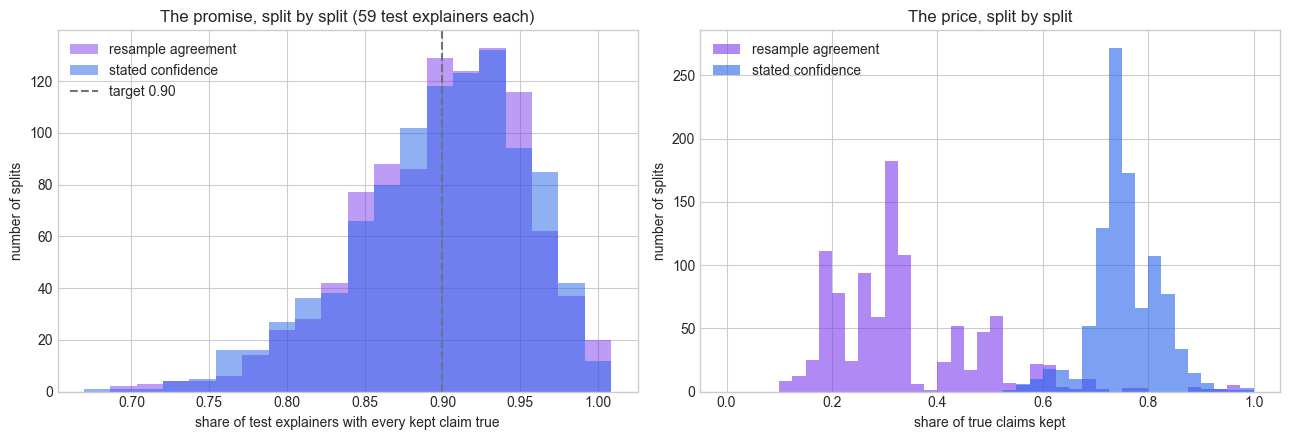

In [10]:
at_alpha = repeated[repeated["score"] != "no filter"]
conf_runs = at_alpha[at_alpha["score"] == "stated confidence"]
false_in_cal = [int(has_false[p[:59]].sum()) for p in SPLITS]
print(f"calibration explainers holding a false claim: median {np.median(false_in_cal):.0f}, "
      f"5th-95th percentile {np.percentile(false_in_cal, 5):.0f} to {np.percentile(false_in_cal, 95):.0f}")
bands = pd.cut(conf_runs["threshold"], [-np.inf, 85, 90, 95, 100, np.inf], right=False)
print("where the stated-confidence threshold lands (share of splits):")
print(bands.value_counts(normalize=True, sort=False).round(3).to_string())
in_90 = conf_runs["threshold"].between(90, 95, inclusive="left")
in_95 = conf_runs["threshold"].between(95, 100, inclusive="left")
print(f"true claims kept, mean: bar in the 90 band {conf_runs.loc[in_90, 'true claims kept'].mean():.3f}, "
      f"bar in the 95 band {conf_runs.loc[in_95, 'true claims kept'].mean():.3f}")
for name, part in at_alpha.groupby("score"):
    print(f"{name:<19} explainers all true, 5th-95th: {part['explainers all true'].quantile(0.05):.3f}"
          f" to {part['explainers all true'].quantile(0.95):.3f} | true claims kept, 5th-95th: "
          f"{part['true claims kept'].quantile(0.05):.3f} to {part['true claims kept'].quantile(0.95):.3f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
bins_cov = (np.arange(40, 61) - 0.5) / 59          # one bin per possible count out of 59
for name, color in [("resample agreement", PURPLE), ("stated confidence", BLUE)]:
    part = at_alpha[at_alpha["score"] == name]
    axes[0].hist(part["explainers all true"], bins=bins_cov, color=color, alpha=0.5, label=name)
    axes[1].hist(part["true claims kept"], bins=np.linspace(0, 1, 41), color=color, alpha=0.6,
                 label=name)
axes[0].axvline(1 - ALPHA, color=GRAY, linestyle="--", label="target 0.90")
axes[0].set_title("The promise, split by split (59 test explainers each)")
axes[0].set_xlabel("share of test explainers with every kept claim true")
axes[0].set_ylabel("number of splits")
axes[0].legend()
axes[1].set_title("The price, split by split")
axes[1].set_xlabel("share of true claims kept")
axes[1].set_ylabel("number of splits")
axes[1].legend()
plt.tight_layout()
plt.show()

This is notebook 03's coverage lottery (section 5 there, field guide §4) at a sample size that
makes it bite. The bar is the sixth-highest explainer score among the calibration explainers,
and a calibration half holds only a median of 12 explainers with any false claim
(9 to 16 across splits). The whole threshold therefore rests on a handful of claims, and it
moves in steps: the stated-confidence bar lands in the 90 band in 85.3% of splits, in the 95
band in 13.9%, and lower in the remaining 0.8%. That step decides the fate of the 247 claims
stated at 90. With the bar inside the 90 level, the jitter publishes a random part of them; with
the bar in the 95 band, none of them is published, and only part of the 226 stated at 95. The
blue histogram on the right shows both cases, a tall hump for the first and a small one near 0.6
to 0.65 for the second: on average the confidence filter keeps 0.770 of the true claims when the
bar sits in the 90 band and 0.664 when it sits in the 95 band. So the price swings: the
confidence filter keeps between 0.643 and 0.856 of the true claims (5th to 95th percentile), the
agreement filter between 0.176 and 0.608.

The promise swings too, from 0.797 to 0.983 for confidence, but read that range with care: it
mixes the calibration lottery with plain test noise, since 59 test explainers measure a 0.90
promise with a standard error of about $\sqrt{0.9 \times 0.1 / 59} \approx 0.039$. The mean
over splits is what the theorem promises; any one deployment is one ticket. Only more graded
explainers shrink the spread.

### Can we learn a better score?

Usefulness is earned by the score, so the obvious move is to engineer a better one: a logistic
regression that predicts "true" from the attribute, the agreement, the stated confidence and
the atomic number. The attribute alone carries real information (four attributes never fail),
and a model could learn to trust a confident symbol more than a confident boiling point.

One caution decides how this must be done. The score must be fixed before calibration. If we
fit it on the calibration explainers, it learns their false claims and gives them flattering
low scores, the bar drops, and the guarantee dies without an error message, which is notebook
01's training-residual sin in a new costume (field guide §2). So we use notebook 02's three-way
split, on explainers: 40 to train the score, 39 to calibrate the bar, 39 to test. We compare on
the same calibration and test explainers, over 300 splits: raw stated confidence; the learned
score with all four inputs; a leaner learned score with attribute and confidence only; and the
other thing we could do with the 40 training explainers, which is to add them to the
calibration set.

In [11]:
ATTRIBUTES = sorted(graded["attribute"].unique())


def claim_features(df, inputs):
    """Design matrix for a learned claim score: one-hot attribute plus chosen numeric inputs."""
    X = pd.get_dummies(df["attribute"]).reindex(columns=ATTRIBUTES, fill_value=0).astype(float)
    if "agreement" in inputs:
        X["agreement"] = df["resample_agreement"] / 5
    if "confidence" in inputs:
        X["confidence"] = df["stated_confidence"] / 100
    if "atomic number" in inputs:
        X["atomic_number"] = df["atomic_number"] / 118
    return X.to_numpy()


VARIANTS = {"learned: attribute, agreement, confidence, atomic number":
                ("attribute", "agreement", "confidence", "atomic number"),
            "learned: attribute, confidence": ("attribute", "confidence")}
conf_score = graded["confidence_score"].to_numpy()       # jittered, as in section 3
conf_raw = graded["stated_confidence"].to_numpy()          # AUC uses raw scores, ties count half
tie_u = np.random.default_rng(RANDOM_SEED + 3).uniform(0, 1, len(graded))
distinct = {name: [] for name in VARIANTS}
rows = []
for perm in SPLITS[:300]:
    train, cal, test = perm[:40], perm[40:79], perm[79:]   # three-way split of explainers
    in_train, in_test = np.isin(unit, train), np.isin(unit, test)
    rows.append({"score": "stated confidence, calibrated on 39",
                 "auc": roc_auc_score(correct[in_test], conf_raw[in_test]),
                 "false claims in training third": int((~correct[in_train]).sum()),
                 **factuality_split(conf_score, correct, unit, cal, test)})
    for name, inputs in VARIANTS.items():
        model = LogisticRegression(max_iter=1000)
        model.fit(claim_features(graded[in_train], inputs), correct[in_train])
        learned = model.predict_proba(claim_features(graded, inputs))[:, 1]
        # A learned score can tie too (one value per attribute and confidence level), so it
        # gets section 3's tie-breaker: a jitter below the smallest gap between two distinct
        # learned values, which orders tied claims and never reorders different ones.
        levels = np.unique(learned)
        distinct[name].append(len(levels))
        learned_score = learned + tie_u * np.diff(levels).min() / 2
        rows.append({"score": name + ", calibrated on 39",
                     "auc": roc_auc_score(correct[in_test], learned[in_test]),
                     **factuality_split(learned_score, correct, unit, cal, test)})
    # The alternative use of the training third: more calibration explainers.
    rows.append({"score": "stated confidence, calibrated on 79 (train + cal)",
                 "auc": roc_auc_score(correct[in_test], conf_raw[in_test]),
                 **factuality_split(conf_score, correct, unit, np.concatenate([train, cal]), test)})
learned_runs = pd.DataFrame(rows)
print(f"false claims available to train on: median "
      f"{learned_runs['false claims in training third'].median():.0f} per training third")
print("distinct learned scores per split, median: " + "; ".join(
    f"{name.split(': ')[1]} {np.median(n):.0f}" for name, n in distinct.items()))
print(f"rank argument with distinct scores and 39 calibration explainers: "
      f"{conformal_rank(39, ALPHA)}/40 = {conformal_rank(39, ALPHA) / 40:.3f}; standard error of each "
      f"mean below: at most {learned_runs.groupby('score')['explainers all true'].sem().max():.4f}")
learned_runs.groupby("score", sort=False).agg(
    explainers_all_true=("explainers all true", "mean"),
    true_claims_kept=("true claims kept", "mean"),
    true_claims_kept_sd=("true claims kept", "std"),
    test_claim_auc=("auc", "mean")).round(3)

false claims available to train on: median 11 per training third
distinct learned scores per split, median: attribute, agreement, confidence, atomic number 1197; attribute, confidence 53
rank argument with distinct scores and 39 calibration explainers: 36/40 = 0.900; standard error of each mean below: at most 0.0039


,explainers_all_true,true_claims_kept,true_claims_kept_sd,test_claim_auc
score,,,,
"stated confidence, calibrated on 39",0.901,0.746,0.089,0.781
"learned: attribute, agreement, confidence, atomic number, calibrated on 39",0.902,0.712,0.147,0.751
"learned: attribute, confidence, calibrated on 39",0.899,0.752,0.113,0.786
"stated confidence, calibrated on 79 (train + cal)",0.902,0.754,0.042,0.781


The engineering idea barely pays, and the first printed line says why: a training third holds
a median of 11 false claims. The four-input model keeps 71.2% of the true claims, against
74.6% for raw stated confidence calibrated on the same 39 explainers, and it ranks test claims
worse (AUC 0.751 against 0.781): with eleven examples of failure, the two extra inputs,
agreement and atomic number, add more noise than signal. The leaner model without them ranks
claims about as well as raw confidence (AUC 0.786) and keeps a little more, 75.2%: knowing that
symbols never fail and boiling points often do is worth under a point here. The second printed
line is section 3's trap again. The leaner model takes a median of only 53 distinct values, one
per attribute and confidence level, so it ties too and gets the same tie-breaker, a jitter
below the smallest gap between two of its values. With the ties broken, the learned rows land
at 0.902 and 0.899, on the 36/40 = 0.900 the rank argument gives for distinct scores and 39
calibration explainers, to within the simulation error printed above.

The winner is the boring row, on steadiness more than on level. Giving the 40 training
explainers to the calibration set instead keeps 75.4% of the true claims, level with the leaner
learned score (75.2%) and above the other two rows, and far more steadily: its standard
deviation across splits is 0.042, against 0.089 for confidence calibrated on 39 and 0.113 and
0.147 for the learned scores. Every row delivers the promise, 0.899 to 0.902, to within the
simulation error. What this does not show is that
learned scores are useless: with thousands of graded explainers a learned score may well win,
and the three-way split is how you would find out. With 118, the scarce resource is graded
failures, and the best place to spend them is the calibration step.

## 5. Units, exchangeability and the grader

The promise is about explainers, so the tile on notebook 03's leaderboard is an explainer. The
tempting alternative is to treat every claim as its own tile: give each claim the score $s(c)$
if it is false and minus infinity if it is true, take the corrected quantile over the claims of
the calibration explainers, and filter. At the claim level that is close to a conformal
procedure with a promise of its own: a new claim is true or filtered out about 90% of the time
or more (approximately, because claims come grouped in explainers, as notebook 09's rows came
grouped in buildings). It is just not the promise the content lead asked for. We commit it on
the same 1,000 splits.

In [12]:
# The mistake, committed: treat each CLAIM as a tile and calibrate on claims.
score = graded["confidence_score"].to_numpy()
s_explainer = explainer_scores(score, correct, unit)
rows = []
for perm in SPLITS:
    cal, test = perm[:59], perm[59:]
    in_cal, in_test = np.isin(unit, cal), np.isin(unit, test)
    claim_scores = np.where(correct, -np.inf, score)          # one tile per claim
    t = corrected_quantile(claim_scores[in_cal], ALPHA)
    kept = in_test & (score > t)
    rows.append({"threshold": t,
                 "test claims kept and false": (kept & ~correct).sum() / in_test.sum(),
                 "test claims kept": kept.sum() / in_test.sum(),
                 "explainers all true": np.mean(s_explainer[test] <= t)})
claim_level = pd.DataFrame(rows)
print(f"claim-level threshold is minus infinity in {np.isinf(claim_level['threshold']).mean():.1%} "
      f"of {N_SPLITS:,} splits")
claim_level.drop(columns="threshold").mean().round(3)

claim-level threshold is minus infinity in 100.0% of 1,000 splits


test claims kept and false    0.027
test claims kept              1.000
explainers all true           0.786
dtype: float64

The claim-level bar is minus infinity in 100.0% of the splits. Since 97.3% of claims are true,
only about 3 claim tiles in 100 are finite, and the corrected quantile lands on minus infinity:
publish everything. The claim-level promise is then met by doing nothing (2.7% of test claims
are published and false, well under 10%), and the explainer-level promise is broken: 0.786 of
test explainers are fully correct, the unfiltered rate. The level of the tile decides which
promise you buy, exactly as rows versus buildings did in notebook 09 (field guide §13). There is
a second reason claims make poor units for this promise: the claims of one explainer share an
element, its fame or obscurity, its history of contested dates. A random claim is not a random
explainer.

Explainers being the units has a consequence of its own. The promise holds for a new explainer
that is exchangeable with the calibration explainers, a random draw from the same bag. The
transuranium elements, atomic numbers 93 to 118, are made in reactors and accelerators (only
neptunium and plutonium also occur in nature, in traces), the heaviest a few atoms at a time;
they are the least studied part of the table and a natural candidate for a different
population. So we calibrate on the 92 elements up
to uranium and deploy on the 26 beyond it.

Two details make the measurement honest. First, the jitter: the bar sits inside a tied level
(agreement 5, confidence 90), so on a fixed calibration and deployment set a single jitter draw
decides which of the tied false claims slip through. We therefore average the deployed promise
over 1,000 fresh jitter draws. Second, a yardstick: 26 explainers is a small test, so we compare
with 200 random splits of the same sizes, each averaged over 50 jitter draws. Counting the
actual split as one of the shuffles, as notebook 09 did in section 5, the share of splits that
do as badly or worse is a permutation p-value. We also try two other cuts, from thorium (atomic number 90) and beyond fermium (100),
to see whether the verdict depends on where the line is drawn.

In [13]:
RAW = {"resample agreement": "resample_agreement", "stated confidence": "stated_confidence"}
shift_rng = np.random.default_rng(RANDOM_SEED + 2)


def promise_over_jitter(raw, cal, test, n_draws):
    """Share of test explainers fully correct after the filter, for n_draws fresh jitters."""
    out = np.empty(n_draws)
    for i in range(n_draws):
        s = explainer_scores(raw + shift_rng.uniform(0, 0.01, len(raw)), correct, unit)
        out[i] = np.mean(s[test] <= corrected_quantile(s[cal], ALPHA))
    return out


is_heavy = graded["atomic_number"].to_numpy() > 92
for label, mask in [("light (Z <= 92)", ~is_heavy), ("heavy (Z >= 93)", is_heavy)]:
    part = graded[mask]
    print(f"{label}: {part['element'].nunique()} explainers, graded claims per explainer "
          f"{part.groupby('element').size().mean():.1f}, with a false claim "
          f"{(~part.groupby('element')['correct'].all()).mean():.1%}, mean stated confidence "
          f"{part['stated_confidence'].mean():.1f}, at agreement 5 "
          f"{(part['resample_agreement'] == 5).mean():.1%}")
n_flawed_heavy = int(has_false[92:].sum())
print(f"random sets of 26 explainers holding {n_flawed_heavy} or more flawed ones: "
      f"{np.mean([has_false[p[:26]].sum() >= n_flawed_heavy for p in SPLITS]):.1%}")

rows = []
for cut in (89, 92, 100):
    cal, test = np.arange(cut), np.arange(cut, N_UNITS)
    for name, col in SCORES.items():
        raw = graded[RAW[name]].to_numpy(dtype=float)
        deployed = promise_over_jitter(raw, cal, test, 1000)
        k = len(test)
        null = np.array([promise_over_jitter(raw, p[k:], p[:k], 50).mean() for p in SPLITS[:200]])
        rows.append({"calibrate on Z <=": cut, "score": name, "deployed explainers": k,
                     "one draw (section 3's)": factuality_split(
                         graded[col].to_numpy(), correct, unit, cal, test)["explainers all true"],
                     "mean over 1,000 draws": deployed.mean(),
                     "draws, 5th pct": np.percentile(deployed, 5),
                     "draws, 95th pct": np.percentile(deployed, 95),
                     "random splits, mean": null.mean(),
                     "random splits, 5th pct": np.percentile(null, 5),
                     # the actual split counts as one of the shuffles (notebook 09, section 5)
                     "permutation p-value": (1 + np.sum(null <= deployed.mean())) / (1 + len(null))})
pd.DataFrame(rows).set_index(["calibrate on Z <=", "score"]).round(3)

light (Z <= 92): 92 explainers, graded claims per explainer 10.9, with a false claim 18.5%, mean stated confidence 95.8, at agreement 5 86.2%
heavy (Z >= 93): 26 explainers, graded claims per explainer 7.6, with a false claim 30.8%, mean stated confidence 91.6, at agreement 5 90.4%
random sets of 26 explainers holding 8 or more flawed ones: 13.7%


deployed explainers  one draw (section 3's)  mean over 1,000 draws  draws, 5th pct  draws, 95th pct  \
calibrate on Z <= score                                                                                                                     
89                resample agreement                   29                   0.759                  0.808           0.724            0.897   
                  stated confidence                    29                   0.759                  0.853           0.759            0.931   
92                resample agreement                   26                   0.808                  0.855           0.769            0.925   
                  stated confidence                    26                   0.769                  0.878           0.808            0.923   
100               resample agreement                   18                   0.833                  0.896           0.833            1.000   
                  stated confidence                    18                   0.833                  0.872           0.833            0.889   

                                      random splits, mean  random splits, 5th pct  permutation p-value  
calibrate on Z <= score                                                                                 
89                resample agreement                0.896                   0.807                0.065  
                  stated confidence                 0.895                   0.790                0.244  
92                resample agreement                0.900                   0.807                0.179  
                  stated confidence                 0.900                   0.793                0.303  
100               resample agreement                0.896                   0.781                0.418  
                  stated confidence                 0.896                   0.779                0.333

The heavy explainers do look different. They carry 7.6 graded claims each against 10.9, 30.8%
of them hold a false claim against 18.5%, and their graded claims come with a lower stated
confidence (91.6 against 95.8). Agreement, tellingly, does not fall: 90.4% of heavy claims sit
at agreement 5, against 86.2% of light ones, so the model is no less consistent about elements
it knows less about. But "look different" is a weak finding at this size: a random set of 26
explainers holds 8 or more flawed ones 13.7% of the time.

The promise sags, in the expected direction and by amounts that 26 explainers cannot resolve.
Calibrated on the light elements and deployed on the transuranium ones, the agreement filter
delivers 0.855 and the confidence filter 0.878, averaged over jitter draws, against 0.900 and
0.900 for random splits of the same sizes; the permutation p-values are 0.179 and 0.303.
Moving the line changes the size of the sag, not the verdict. From thorium on, the agreement
filter falls to 0.808 with a permutation p-value of 0.065; that is the closest any row comes to
a signal, and among six rows examined, one this close to 0.05 is what luck alone often produces.
The confidence filter falls to 0.853 there. Beyond fermium the 18 explainers deliver 0.896 and
0.872, both well within luck. Look also at the single-draw column: the jitter from section 3
gave the confidence filter 0.769 on the transuranium elements, below the 5th percentile of the
1,000 draws (0.808; the 95th is 0.923). One draw of a coin, on a fixed small deployment, can make a working filter
look broken or a broken one look fine.

So the honest conclusion is not "the promise breaks for heavy elements" and not "it holds". It
is that we have not shown either, and that is not the same as exchangeability. A quiet test is
not proof (notebook 09, section 5): the sag is two to five points at the transuranium cut, while
one random split in twenty already lands at 0.807 or lower for agreement and 0.793 for confidence,
so only a much larger break would stand out. A promise for a population you did not calibrate
on is a hope. The next cell shows why the measured sag is probably flattering.

In [14]:
ungradable = claims[~claims["gradable"]]
light_threshold = factuality_split(graded["confidence_score"].to_numpy(), correct, unit,
                                   np.arange(92), np.arange(92, N_UNITS))["threshold"]
heavy_ungradable = ungradable[ungradable["atomic_number"] > 92]
print(f"ungradable claims: {len(ungradable)} in all, {len(heavy_ungradable)} of them about "
      f"transuranium elements (median atomic number {ungradable['atomic_number'].median():.0f})")
print(f"their mean stated confidence: {ungradable['stated_confidence'].mean():.1f} "
      f"(gradable claims: {graded['stated_confidence'].mean():.1f})")
survive = heavy_ungradable["confidence_score"] > light_threshold
print(f"of the {len(heavy_ungradable)} transuranium ungradable claims, the light-calibrated "
      f"confidence filter (threshold {light_threshold:.3f}) would keep {int(survive.sum())}")
missing = pubchem.set_index("AtomicNumber")[["MeltingPoint", "BoilingPoint", "Density",
                                              "Electronegativity", "IonizationEnergy"]].isna()
missing.groupby(np.where(missing.index > 92, "Z >= 93", "Z <= 92")).sum()

ungradable claims: 99 in all, 87 of them about transuranium elements (median atomic number 108)
their mean stated confidence: 56.9 (gradable claims: 95.1)
of the 87 transuranium ungradable claims, the light-calibrated confidence filter (threshold 90.005) would keep 1


,MeltingPoint,BoilingPoint,Density,Electronegativity,IonizationEnergy
Z <= 92,0,3,1,8,0
Z >= 93,15,22,21,15,16


The grader is silent exactly where Quill is least sure. Of the 99 ungradable claims, 87 are
about transuranium elements (their median atomic number is 108), and their mean stated
confidence is 56.9, against 95.1 for the gradable claims. PubChem's own table has no melting
point for 15 of the 26 transuranium elements, no boiling point for 22, no density for 21, no
electronegativity for 15 and no ionization energy for 16. So the heavy explainers we could grade
are mostly their identity facts (number, symbol, mass, state, group, year), the easy part, and
the measured promise for heavy elements is a promise about the easy part. The physics, where
the model writes numbers it rates at 50 or 60, is outside it.

In practice the filter would have spared us: the light-calibrated confidence filter (bar
90.005) keeps 1 of the 87 heavy ungradable claims, because they are stated with so little
confidence. The ungradable-claims policy and the filter agree almost everywhere here. They need
not agree on the next model, which may state its guesses at 95; that one surviving claim is
exactly the kind a human reviewer has to see.

The last ingredient of the promise is the grader itself. "True" in every number above means
"accepted by `grade`", with its 5% on melting points and its 2 years on discovery dates. A
stricter reviewer is easy to imagine: halve every numeric tolerance, require discovery years to
match exactly. We copy the course grader verbatim, confirm it reproduces all 1,296 labels, write
the stricter one next to it, and ask two questions: what happens to a filter calibrated with the
course grader when the strict reviewer judges its output, and what does recalibrating cost?

In [15]:
# The grader, copied verbatim from llm_data/generate_llm_data.ipynb.
def num(x):
    """The first number in a value, scientific notation included (8.988e-05 stays 8.988e-05)."""
    m = re.search(r"[-+]?(\d+\.?\d*|\.\d+)([eE][-+]?\d+)?", str(x).replace(",", ""))
    return float(m.group()) if m else None


def grade(attribute, claimed, truth):
    """True / False against PubChem, or None when PubChem has no value to check against."""
    if truth is None or (isinstance(truth, float) and math.isnan(truth)) or str(truth).strip() == "":
        return None
    c, t = str(claimed).strip().lower(), str(truth).strip().lower()
    if attribute in ("symbol", "standard_state", "group_block"):
        t = t.replace("expected to be a ", "")
        return c == t
    if attribute == "year_discovered":
        if t == "ancient":
            return "ancient" in c or (num(c) is not None and num(c) < 1600)
        return num(c) is not None and abs(num(c) - float(t)) <= 2
    if attribute == "atomic_number":                    # a whole number, no truncation
        return bool(re.fullmatch(r"\d+", c)) and int(c) == int(float(t))
    if not re.fullmatch(r"[-+]?(\d+\.?\d*|\.\d+)([eE][-+]?\d+)?", c.replace(",", "")):
        return None   # not a bare number in the requested unit: ungradable, never "true"
    # Relative tolerances. Atomic mass gets 1% because PubChem rounds some standard masses
    # (lithium is listed as 7.0, where textbooks print 6.94).
    tol = {"atomic_mass": 0.01, "melting_point": 0.05, "boiling_point": 0.05, "density": 0.05,
           "ionization_energy": 0.03}.get(attribute)
    if attribute == "electronegativity":
        return num(c) is not None and abs(num(c) - float(t)) <= 0.1
    return num(c) is not None and abs(num(c) - float(t)) <= tol * abs(float(t))


regraded = [grade(a, c, t) for a, c, t in zip(claims["attribute"], claims["claimed_value"],
                                              claims["true_value"])]
assert all((r is None and pd.isna(o)) or r == o for r, o in zip(regraded, claims["correct"])), \
    "the copied grader must reproduce every label in the file"

STRICT_TOLERANCE = {"atomic_mass": 0.005, "melting_point": 0.025, "boiling_point": 0.025,
                    "density": 0.025, "ionization_energy": 0.015}


def grade_strict(attribute, claimed, truth):
    """A stricter reviewer: every numeric tolerance halved, discovery years matched exactly."""
    verdict = grade(attribute, claimed, truth)
    if not verdict:                                   # None (ungradable) and False stay
        return verdict
    t = str(truth).strip().lower()
    if attribute in STRICT_TOLERANCE:
        return abs(num(claimed) - float(t)) <= STRICT_TOLERANCE[attribute] * abs(float(t))
    if attribute == "electronegativity":
        return abs(num(claimed) - float(t)) <= 0.05
    if attribute == "year_discovered" and t != "ancient":
        return num(claimed) == float(t)
    return verdict


strict = np.array([grade_strict(a, c, t) for a, c, t in zip(
    graded["attribute"], graded["claimed_value"], graded["true_value"])], dtype=bool)
print(f"copied grader reproduces all {len(claims):,} labels")
flawed_strict = ~pd.Series(strict).groupby(unit).all()
print(f"claims correct: {correct.mean():.1%} under the course grader, {strict.mean():.1%} "
      f"under the strict one")
print(f"explainers with a false claim: {int((~explainer_ok).sum())} ({(~explainer_ok).mean():.1%}) "
      f"vs {int(flawed_strict.sum())} ({flawed_strict.mean():.1%})")

rows = []
for perm in SPLITS:
    cal, test = perm[:59], perm[59:]
    in_test = np.isin(unit, test)
    for name, col in SCORES.items():
        score = graded[col].to_numpy()
        s_course = explainer_scores(score, correct, unit)
        s_strict = explainer_scores(score, strict, unit)
        t_course = corrected_quantile(s_course[cal], ALPHA)
        t_strict = corrected_quantile(s_strict[cal], ALPHA)
        rows.append({"score": name,
                     "calibrated course, judged course": np.mean(s_course[test] <= t_course),
                     "calibrated course, judged strict": np.mean(s_strict[test] <= t_course),
                     "calibrated strict, judged strict": np.mean(s_strict[test] <= t_strict),
                     "true claims kept, course": ((score > t_course) & in_test & correct).sum()
                                                 / (in_test & correct).sum(),
                     "true claims kept, strict": ((score > t_strict) & in_test & strict).sum()
                                                 / (in_test & strict).sum()})
pd.DataFrame(rows).groupby("score").mean().T.round(3)

copied grader reproduces all 1,296 labels
claims correct: 97.3% under the course grader, 96.6% under the strict one
explainers with a false claim: 25 (21.2%) vs 31 (26.3%)


score,resample agreement,stated confidence
"calibrated course, judged course",0.899,0.898
"calibrated course, judged strict",0.891,0.872
"calibrated strict, judged strict",0.899,0.898
"true claims kept, course",0.343,0.756
"true claims kept, strict",0.312,0.716


Halving the tolerances moves claim accuracy only from 97.3% to 96.6%, but it moves the share of
flawed explainers from 21.2% to 26.3%: six more explainers now contain an error, because every
explainer has ten chances to trip a stricter rule. A filter calibrated with the course grader
and judged by the strict reviewer delivers 0.891 (agreement) and 0.872 (confidence) instead of
0.899 and 0.898; both slip under the 0.90 target, the confidence filter by almost three points.
Recalibrating against the strict grader restores the promise (0.899 and 0.898) and costs true
claims: the confidence filter's share falls from 75.6% to 71.6%, the agreement filter's from
34.3% to 31.2%.

The effect is small here, and we say so; the principle is not small. Every promise in this
notebook reads, in full, "every published claim is accepted by this grader, with these
tolerances, against this reference, in nine explainers out of ten". A wrong reference value or
an ambiguous definition (helium's year) is part of the promise, not an exception to it, and a
change of grader is a change of procedure that requires recalibration (field guide §25, field
guide §27). The recipe we built also has a known limit: one bar for every explainer, and a promise
averaged over explainers rather than held for each kind of explainer; a published extension that
relaxes both is named in section 4, next to the price of one bar for all.

The four promises this notebook touched, side by side:

| Promise | What it says | Measured for Quill here | Pitfall |
|---|---|---|---|
| per claim | a new claim is true or filtered out about 90% of the time or more | met with no filter: 2.7% of claims are false | 21.2% of explainers still contain an error |
| per explainer (conformal factuality) | a new explainer's published claims are all true with probability at least 0.9 | 0.898 with stated confidence, keeping 75.6% of true claims | says nothing about which explainer fails (ruthenium) or about any single claim |
| per population (heavy elements) | not promised by the recipe | 0.878 on 26 transuranium explainers; too few to tell | quoting a light-calibrated promise for a population you never calibrated on |
| per grader | the promise holds against the grader used to calibrate | 0.872 when a stricter reviewer judges the same filter | publishing the promise without its grader and tolerances |

## 6. Common mistakes to avoid

1. **Promising per claim when the business asks per answer.** 97.3% of Quill's claims are true
   and 21.2% of its explainers contain a false one. A claim-level calibration returned a bar of
   minus infinity in every split and filtered nothing. Decide the unit of the promise first: the
   explainer (field guide §27, field guide §13).
2. **Letting ties decide silently.** With raw agreement the bar was exactly 5.0 and the filter
   published empty explainers. Break ties with a tiny jitter, and when you evaluate one fixed
   deployment, average over jitter draws: a single draw gave the transuranium deployment 0.769
   where the average was 0.878.
3. **Mistaking consistency for truth.** 22 of the 32 false claims were repeated by all five
   resampled profiles. Agreement kept the promise but only 34.3% of the true claims, against
   75.6% for stated confidence (field guide §24, field guide §5).
4. **Fitting the score where you calibrate, or spending scarce failures on a learned score.**
   The score must come from separate data, which means a three-way split. With a median of 11
   false claims to learn from, the two learned scores kept 71.2% and 75.2% of true claims,
   against 74.6% for raw stated confidence on the same calibration explainers; the same 40
   explainers spent on calibration instead kept 75.4%, and varied far less from split to split
   (field guide §2).
5. **Publishing the promise without its grader.** "True" means accepted by a stated grader;
   a stricter reviewer turned 0.898 into 0.872. Print the tolerances and known ambiguities next
   to the promise, and recalibrate when the grader changes (field guide §27, field guide §25).
6. **Carrying the promise to a population you did not calibrate on.** On 26 transuranium
   explainers the promise sagged to 0.855 or 0.878, a gap 26 explainers cannot resolve, and the
   hardest heavy claims could not be graded at all. Calibrate on the population you publish for
   (field guide §26, field guide §13).

## 7. What to say in the product review

**Strong version**

> We publish element explainers through a factuality filter calibrated on 59 graded explainers.
> Across 1,000 random splits, 89.8% of held-out explainers had every published claim correct,
> our 90% target to within the simulation's precision; single splits of 59 held-out explainers
> ranged from 80% to 98% (5th to 95th percentile).
> The filter ranks claims by the model's stated confidence and publishes 76% of the true claims,
> about three in four of each explainer's claims; ranking by resample agreement keeps the same
> promise with 34%. A 95% promise would cost more: 60% of the true claims kept instead of 76%.
> "Correct" means the value each claim returns, not its sentence, is accepted by our PubChem
> grader: within 5% on melting and boiling points and
> densities, within 2 years on discovery dates, which counts several defensible discovery
> years as wrong. Claims PubChem cannot check (99 here, 87 of them about transuranium elements)
> fall outside the promise; the filter keeps few of them (1 of 87) and we withhold those until a
> reviewer confirms them. The promise is an average over explainers like the
> calibration set; we have not shown it for the superheavy elements, and we recalibrate after
> any change to the model, the prompt or the grader.

**Weak version**

> Our fact filter makes Quill 90% accurate, so nine out of ten facts we publish are right, and
> the model is 95% confident on what remains.

The weak version gets the unit wrong twice: the promise is about whole explainers, not facts, and nine facts in ten would have been met by doing nothing (97.3% of claims were
already true). It hides the price (24% of the true claims thrown away) and the grader that
defines "right", it says nothing about which population the promise covers, and it quotes the
model's stated confidence, which the filter used only as a ranking, as if it were a probability.

### The one-line summary

A long answer is a bundle of claims, and the promise a content team needs is about the bundle:
every published claim true, in nine explainers out of ten. Conformal factuality buys it with
one number per explainer, the score of its most convincing false claim, and notebook 02's
corrected quantile of those numbers: publish only what scores above it. The promise is free for
any score; how much of the truth survives is earned by the score, paid for in calibration data,
and defined by the grader.

A shorter explainer that is right beats a longer one that is probably right.